In [354]:
import numpy as np
import pandas as pd

In [355]:
df = pd.read_csv('placement.csv')
df

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0
...,...,...,...,...
95,95,4.3,200.0,0
96,96,4.4,42.0,0
97,97,6.7,182.0,1
98,98,6.3,103.0,1


# 0. Preprocess + EDA + Feature Selection

### Preprocess

In [356]:
df = df.iloc[:, 1:]
df

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0
...,...,...,...
95,4.3,200.0,0
96,4.4,42.0,0
97,6.7,182.0,1
98,6.3,103.0,1


In [357]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [358]:
df.columns

Index(['cgpa', 'iq', 'placement'], dtype='str')

In [359]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       100 non-null    float64
 1   iq         100 non-null    float64
 2   placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


### EDA

In [360]:
import matplotlib.pyplot as plt


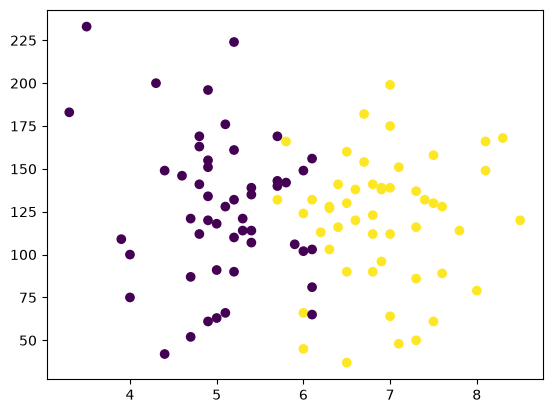

In [361]:
plt.scatter(df['cgpa'], df['iq'], c=df['placement'])

### Feature Selection

# 1. Extract input and output cols


In [362]:
X = df.iloc[:, 0:2]
y = df.iloc[:, 2]

In [363]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [364]:
X.shape

(100, 2)

In [365]:
y

0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64

In [366]:
y.shape

(100,)

# 2. Train test split


In [367]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1)

In [368]:
X_train

,cgpa,iq
67,5.0,118.0
83,7.5,130.0
26,7.0,199.0
97,6.7,182.0
45,6.0,66.0
...,...,...
75,4.8,169.0
14,6.1,103.0
3,7.4,132.0
94,4.7,52.0


In [369]:
y_train

67    0
83    1
26    1
97    1
45    1
     ..
75    0
14    0
3     1
94    0
98    1
Name: placement, Length: 90, dtype: int64

In [370]:
X_test

,cgpa,iq
59,4.8,112.0
89,4.9,151.0
78,6.1,81.0
6,5.7,143.0
32,7.0,139.0
82,6.5,37.0
19,5.2,132.0
51,4.8,141.0
39,4.6,146.0
48,6.6,138.0


# 3. Scale the values


In [371]:
from sklearn.preprocessing import StandardScaler

scaled = StandardScaler()

In [372]:
X_train_scaled = scaled.fit_transform(X_train)
X_train_scaled

array([[-0.89024175, -0.14287029],
       [ 1.26588735,  0.15500599],
       [ 0.83466153,  1.86779463],
       [ 0.57592604,  1.44580322],
       [-0.02779011, -1.43366752],
       [-1.40771273,  0.62664344],
       [-0.20028044,  0.45288228],
       [-0.02779011,  0.62664344],
       [ 1.52462284, -0.24216239],
       [-0.80399658, -1.43366752],
       [-0.2865256 ,  0.20465204],
       [ 1.69711317, -1.11096822],
       [-2.1839192 ,  2.71177743],
       [-0.97648691,  0.25429809],
       [ 0.14470022, -0.26698541],
       [-0.80399658,  0.10535994],
       [ 0.92090669,  0.67628949],
       [-1.14897724, -0.91238403],
       [-1.75269338, -1.21026031],
       [ 1.78335833,  1.04863484],
       [-2.35640953,  1.47062625],
       [-0.54526109,  0.37841321],
       [ 0.83466153, -0.29180843],
       [-1.14897724, -0.06840122],
       [ 0.6621712 , -0.83791495],
       [ 1.35213251,  0.10535994],
       [-0.2865256 ,  1.12310392],
       [ 0.23094538,  0.10535994],
       [-0.02779011,

In [373]:
X_test_scaled = scaled.transform(X_test)
X_test_scaled

array([[-1.06273207, -0.29180843],
       [-0.97648691,  0.67628949],
       [ 0.05845506, -1.06132217],
       [-0.2865256 ,  0.4777053 ],
       [ 0.83466153,  0.37841321],
       [ 0.40343571, -2.15353521],
       [-0.71775142,  0.20465204],
       [-1.06273207,  0.42805925],
       [-1.2352224 ,  0.55217437],
       [ 0.48968087,  0.35359018]])

# 4. Train the model


In [374]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

In [375]:
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [376]:
y_pred = model.predict(X_test_scaled)
y_pred

array([0, 0, 1, 0, 1, 1, 0, 0, 0, 1])

In [377]:
y_test

59    0
89    0
78    0
6     0
32    1
82    1
19    0
51    0
39    0
48    1
Name: placement, dtype: int64

In [378]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)
print(f"Accuracy of the model is: {accuracy_score(y_test, y_pred)}")

Accuracy of the model is: 0.9


<Axes: >

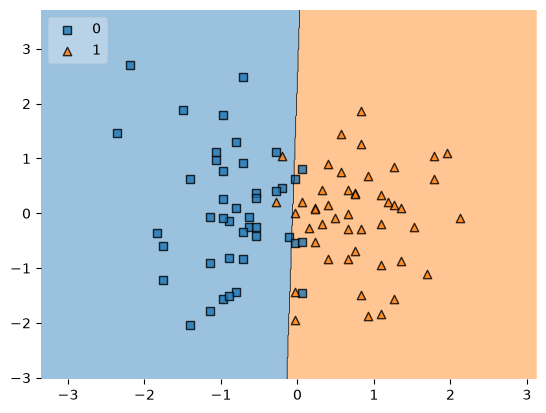

In [379]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X_train_scaled, y_train.values, clf=model, legend=2)


# 5. Evaluate the model/model selection

# 6. Deploy the model

In [380]:
import pickle

pickle.dump(model, open('model.pkl', 'wb'))